In [ ]:
import os
import numpy as np
import pandas as pd
import nibabel as nib
from pathlib import Path
from scipy.ndimage import zoom
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import pickle

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {len(tf.config.list_physical_devices('GPU')) > 0}")

TensorFlow Version: 2.19.0
GPU Available: True


In [ ]:
BASE_DIR = Path("/content/drive/MyDrive/Colab Notebooks/lung_cancer")
LABELS_CSV = BASE_DIR / "labels_TTF1_CK7.csv"
MANIFEST_CSV = "/content/drive/MyDrive/Colab Notebooks/processed/manifest_preproc.csv"
RADIOMICS_DIR = BASE_DIR / "radiomics_ct"
MODEL_SAVE_PATH = BASE_DIR / "model_whole_ct_tf.keras"
$

TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 4
EPOCHS = 50
LR = 1e-4

PREFERRED_CT_SOURCE = "nifti"
print(f"Sursa CT selectată: {PREFERRED_CT_SOURCE} (Whole CT)")

Sursa CT selectată: nifti (Whole CT)


In [ ]:
def _norm_code(x: str) -> str:
    return pd.Series([x]).astype(str).str.extract(r"(\d+)")[0].iloc[0]

def _pick_ct_path(row, preferred="nifti"):
    candidates_order = [
        "ct_nifti_path",
        "ct_cropped_nifti_path",
        "ct_npy_path"
    ]

    chosen_col, chosen_path = None, None
    for col in candidates_order:
        if col in row and pd.notna(row[col]) and str(row[col]).strip():
            p = str(row[col]).strip()
            if os.path.exists(p):
                chosen_col, chosen_path = col, p
                break
    return chosen_col, chosen_path

def load_data_index(labels_path, manifest_path):
    lbl = pd.read_csv(labels_path, dtype=str)
    lbl["Code"] = lbl["Code"].apply(_norm_code)
    for c in ["TTF1", "CK7"]:
        lbl[c] = pd.to_numeric(lbl[c], errors="coerce")

    man = pd.read_csv(manifest_path, dtype=str)
    man.columns = [c.strip() for c in man.columns]
    if "Code" not in man.columns:
         alt = [c for c in man.columns if c.lower() == "code"]
         if alt: man.rename(columns={alt[0]: "Code"}, inplace=True)
    man["Code"] = man["Code"].apply(_norm_code)

    df = lbl.dropna(subset=["TTF1", "CK7"]).merge(man, on="Code", how="inner")

    paths, sources, rad_paths = [], [], []
    valid_mask = []

    for _, row in df.iterrows():
        col, p = _pick_ct_path(row, preferred=PREFERRED_CT_SOURCE)
        rad_p = RADIOMICS_DIR / f"{row['Code']}_radiomics.txt"

        is_valid = (p is not None) and os.path.exists(p) and rad_p.exists()

        paths.append(p)
        sources.append(col)
        rad_paths.append(str(rad_p))
        valid_mask.append(is_valid)

    df["ct_path"] = paths
    df["ct_source"] = sources
    df["radiomics_path"] = rad_paths

    return df[valid_mask].copy()

df_index = load_data_index(LABELS_CSV, MANIFEST_CSV)
print(f"Pacienți valizi găsiți: {len(df_index)}")
print(df_index["ct_source"].value_counts())

Pacienți valizi găsiți: 87
ct_source
ct_nifti_path    87
Name: count, dtype: int64


In [ ]:
def load_ct_volume(path, target_shape=(128, 128, 128)):
    img = nib.load(path)
    vol = img.get_fdata().astype(np.float32)

    vol = np.clip(vol, -1000, 400)

    vol = (vol - vol.min()) / (vol.max() - vol.min() + 1e-6)

    factors = (
        target_shape[0] / vol.shape[0],
        target_shape[1] / vol.shape[1],
        target_shape[2] / vol.shape[2]
    )
    vol_resized = zoom(vol, factors, order=1)

    return vol_resized[..., np.newaxis]

def load_radiomics(path):
    feats = {}
    with open(path, "r") as f:
        for line in f:
            if ":" in line:
                k, v = line.strip().split(":", 1)
                try:
                    val = float(v.replace("np.float64(", "").replace(")", "").strip())
                    if k.strip().startswith("original_"):
                        feats[k.strip()] = val
                except: continue
    return feats


X_ct_list = []
X_rad_list = []
y_list = []

print("Încărcare și procesare volume... (poate dura câteva minute)")
radiomics_data = []

for idx, row in df_index.iterrows():
    # 1. CT
    vol = load_ct_volume(row["ct_path"], TARGET_SHAPE)
    X_ct_list.append(vol)

    # 2. Radiomics
    rad_feats = load_radiomics(row["radiomics_path"])
    radiomics_data.append(rad_feats)

    # 3. Labels
    y_list.append([row["TTF1"], row["CK7"]])

X_ct = np.array(X_ct_list)
y = np.array(y_list, dtype=np.float32)
df_rad = pd.DataFrame(radiomics_data).fillna(0)
X_rad = df_rad.select_dtypes(include=[np.number]).values

scaler = StandardScaler()
X_rad = scaler.fit_transform(X_rad)

print(f"Shape CT: {X_ct.shape}")
print(f"Shape Radiomics: {X_rad.shape}")
print(f"Shape Labels: {y.shape}")

Încărcare și procesare volume... (poate dura câteva minute)
Shape CT: (87, 128, 128, 128, 1)
Shape Radiomics: (87, 107)
Shape Labels: (87, 2)


In [ ]:
stratify_key = df_index["TTF1"].astype(str) + "_" + df_index["CK7"].astype(str)

X_ct_train, X_ct_rem, X_rad_train, X_rad_rem, y_train, y_rem = train_test_split(
    X_ct, X_rad, y, test_size=0.20, stratify=stratify_key, random_state=SEED
)

stratify_rem = [str(int(i[0])) + "_" + str(int(i[1])) for i in y_rem]

X_ct_val, X_ct_test, X_rad_val, X_rad_test, y_val, y_test = train_test_split(
    X_ct_rem, X_rad_rem, y_rem, test_size=0.50, stratify=stratify_rem, random_state=SEED
)

print(f"Train: {len(y_train)} | Val: {len(y_val)} | Test: {len(y_test)}")

def create_tf_dataset(x_ct, x_rad, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(((x_ct, x_rad), {"TTF1": y[:, 0], "CK7": y[:, 1]}))
    if shuffle:
        ds = ds.shuffle(len(y))
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = create_tf_dataset(X_ct_train, X_rad_train, y_train, shuffle=True)
val_ds = create_tf_dataset(X_ct_val, X_rad_val, y_val)
test_ds = create_tf_dataset(X_ct_test, X_rad_test, y_test)

Train: 69 | Val: 9 | Test: 9


In [ ]:
def build_custom_model(input_shape_ct, input_shape_rad):
    in_ct = layers.Input(shape=input_shape_ct, name="input_ct")
    in_rad = layers.Input(shape=(input_shape_rad,), name="input_rad")



    x = layers.Conv3D(16, (3,3,3), padding="same")(in_ct)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv3D(16, (3,3,3), padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling3D(2)(x)

    x = layers.Conv3D(32, (3,3,3), padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv3D(32, (3,3,3), padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling3D(2)(x)

    x = layers.Conv3D(64, (3,3,3), padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv3D(64, (3,3,3), padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling3D(2)(x)

    x = layers.Conv3D(128, (3,3,3), padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.GlobalAveragePooling3D()(x)

    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    r = layers.Dense(256, activation="relu")(in_rad)
    r = layers.Dropout(0.3)(r)
    r = layers.Dense(128, activation="relu")(r)

    z = layers.Concatenate()([x, r])
    z = layers.Dense(128, activation="relu")(z)
    z = layers.Dropout(0.4)(z)

    out_ttf1 = layers.Dense(1, activation="sigmoid", name="TTF1")(z)
    out_ck7 = layers.Dense(1, activation="sigmoid", name="CK7")(z)

    model = models.Model(inputs=[in_ct, in_rad], outputs={"TTF1": out_ttf1, "CK7": out_ck7})
    return model

model = build_custom_model(input_shape_ct=TARGET_SHAPE+(1,), input_shape_rad=X_rad.shape[1])
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ct            │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_14 (Conv3D)  │ (None, 128, 128,  │        448 │ input_ct[0][0]    │
│                     │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         64 │ conv3d_14[0][0]   │
│ (BatchNormalizatio… │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_14       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_15 (Conv3D)  │ (None, 128, 128,  │      6,928 │ activation_14[0]… │
│                     │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         64 │ conv3d_15[0][0]   │
│ (BatchNormalizatio… │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_15       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_6     │ (None, 64, 64,    │          0 │ activation_15[0]… │
│ (MaxPooling3D)      │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_16 (Conv3D)  │ (None, 64, 64,    │     13,856 │ max_pooling3d_6[… │
│                     │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv3d_16[0][0]   │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_16       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_17 (Conv3D)  │ (None, 64, 64,    │     27,680 │ activation_16[0]… │
│                     │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv3d_17[0][0]   │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_17       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_7     │ (None, 32, 32,    │          0 │ activation_17[0]… │
│ (MaxPooling3D)      │ 32, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_18 (Conv3D)  │ (None, 32, 32,    │     55,360 │ max_pooling3d_7[… │
│                     │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv3d_18[0][0] 

 Total params: 547,858 (2.09 MB)

 Trainable params: 547,154 (2.09 MB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:
model.compile(
    optimizer=optimizers.Adam(learning_rate=LR),
    loss={"TTF1": "binary_crossentropy", "CK7": "binary_crossentropy"},
    metrics={"TTF1": "accuracy", "CK7": "accuracy"}
)

cb_list = [
    callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, verbose=1),
    callbacks.ModelCheckpoint(MODEL_SAVE_PATH, monitor="val_loss", save_best_only=True, verbose=1)
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=cb_list
)

Epoch 1/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - CK7_accuracy: 0.4479 - CK7_loss: 0.7161 - TTF1_accuracy: 0.4436 - TTF1_loss: 0.7061 - loss: 1.4221   
Epoch 1: val_loss improved from inf to 1.33788, saving model to /content/drive/MyDrive/Colab Notebooks/lung_cancer/model_whole_ct_tf.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - CK7_accuracy: 0.4480 - CK7_loss: 0.7156 - TTF1_accuracy: 0.4446 - TTF1_loss: 0.7061 - loss: 1.4217 - val_CK7_accuracy: 0.4444 - val_CK7_loss: 0.6852 - val_TTF1_accuracy: 0.7778 - val_TTF1_loss: 0.6371 - val_loss: 1.3379 - learning_rate: 1.0000e-04
Epoch 2/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 570ms/step - CK7_accuracy: 0.5368 - CK7_loss: 0.6663 - TTF1_accuracy: 0.6551 - TTF1_loss: 0.6596 - loss: 1.3256
Epoch 2: val_loss improved from 1.33788 to 1.32700, saving model to /content/drive/MyDrive/Colab Notebooks/lung_cancer/model_whole_ct_tf.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 11s 609ms/step - CK7_accuracy: 0.5360 - CK7_loss: 0.6665 - TTF1_accuracy: 0.6549 - TTF1_loss: 0.

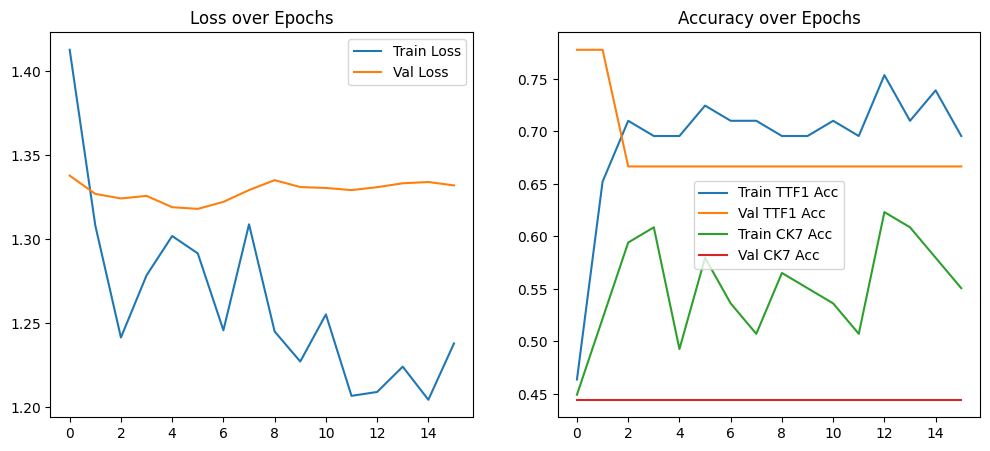

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step

--- RAPORT TEST SET ---
TTF1 Accuracy: 0.6667
CK7 Accuracy:  0.6667

Classification Report TTF1:
              precision    recall  f1-score   support

         0.0       0.50      0.33      0.40         3
         1.0       0.71      0.83      0.77         6

    accuracy                           0.67         9
   macro avg       0.61      0.58      0.58         9
weighted avg       0.64      0.67      0.65         9


Classification Report CK7:
              precision    recall  f1-score   support

         0.0       1.00      0.40      0.57         5
         1.0       0.57      1.00      0.73         4

    accuracy                           0.67         9
   macro avg       0.79      0.70      0.65         9
weighted avg       0.81      0.67      0.64         9



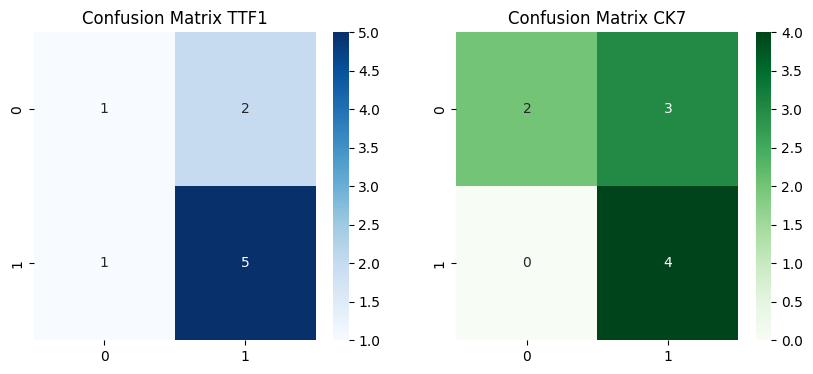

In [ ]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['TTF1_accuracy'], label='Train TTF1 Acc')
plt.plot(history.history['val_TTF1_accuracy'], label='Val TTF1 Acc')
plt.plot(history.history['CK7_accuracy'], label='Train CK7 Acc')
plt.plot(history.history['val_CK7_accuracy'], label='Val CK7 Acc')
plt.title('Accuracy over Epochs')
plt.legend()
plt.show()

preds = model.predict(test_ds)
y_pred_ttf1 = (preds["TTF1"] > 0.58).astype(int).ravel() #58
y_pred_ck7 = (preds["CK7"] > 0.4915).astype(int).ravel() #53

y_true_ttf1 = y_test[:, 0]
y_true_ck7 = y_test[:, 1]

print("\n--- RAPORT TEST SET ---")
print(f"TTF1 Accuracy: {accuracy_score(y_true_ttf1, y_pred_ttf1):.4f}")
print(f"CK7 Accuracy:  {accuracy_score(y_true_ck7, y_pred_ck7):.4f}")

print("\nClassification Report TTF1:")
print(classification_report(y_true_ttf1, y_pred_ttf1))

print("\nClassification Report CK7:")
print(classification_report(y_true_ck7, y_pred_ck7))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(confusion_matrix(y_true_ttf1, y_pred_ttf1), annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title("Confusion Matrix TTF1")
sns.heatmap(confusion_matrix(y_true_ck7, y_pred_ck7), annot=True, fmt='d', cmap='Greens', ax=ax[1])
ax[1].set_title("Confusion Matrix CK7")
plt.show()

In [ ]:
from sklearn.metrics import precision_recall_curve, roc_curve

def find_optimal_threshold(y_true, y_prob, name, metric='f1'):
    if metric == 'f1':
        precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
        f1_scores = 2 * (precision * recall) / (precision + recall + 1e-6)
        ix = np.argmax(f1_scores)
        best_thresh = thresholds[ix]
        best_score = f1_scores[ix]
        print(f"[{name}] Best Threshold (F1-max): {best_thresh:.4f}, F1-Score: {best_score:.4f}")

    elif metric == 'youden':
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)
        j_scores = tpr - fpr
        ix = np.argmax(j_scores)
        best_thresh = thresholds[ix]
        best_score = j_scores[ix]
        print(f"[{name}] Best Threshold (Youden): {best_thresh:.4f}, J-Score: {best_score:.4f}")

    return best_thresh

preds = model.predict(test_ds, verbose=0)
prob_ttf1 = preds["TTF1"].ravel()
prob_ck7 = preds["CK7"].ravel()

thresh_ttf1 = find_optimal_threshold(y_true_ttf1, prob_ttf1, "TTF1", metric='f1')
thresh_ck7 = find_optimal_threshold(y_true_ck7, prob_ck7, "CK7", metric='f1')

y_pred_final_ttf1 = (prob_ttf1 >= thresh_ttf1).astype(int)
y_pred_final_ck7 = (prob_ck7 >= thresh_ck7).astype(int)

print(f"TTF1 Accuracy: {accuracy_score(y_true_ttf1, y_pred_final_ttf1):.4f}")
print(f"CK7 Accuracy:  {accuracy_score(y_true_ck7, y_pred_final_ck7):.4f}")

print("\nMatrice Confuzie TTF1:")
print(confusion_matrix(y_true_ttf1, y_pred_final_ttf1))

print("\nMatrice Confuzie CK7:")
print(confusion_matrix(y_true_ck7, y_pred_final_ck7))

[TTF1] Best Threshold (F1-max): 0.5713, F1-Score: 0.8000
[CK7] Best Threshold (F1-max): 0.4915, F1-Score: 0.7273
TTF1 Accuracy: 0.6667
CK7 Accuracy:  0.6667

Matrice Confuzie TTF1:
[[0 3]
 [0 6]]

Matrice Confuzie CK7:
[[2 3]
 [0 4]]
